In [1]:
import pandas as pd

#sklearn: Train machine-learning models
from sklearn.compose import ColumnTransformer, make_column_selector
# columnTransformer: "Apply this transformation to these columns
# , and a different transformation to those columns.
# make_column_selector: helper to columnTransformer.Select columns that are numeric
# ,and select those that aren't numeric.

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
# LogisticRegression = Learn from past customers and estimate whether this new customer will churn.
# It can also output a probability of churn, e.g. 0.82 → 82% chance of churn.
# ,You can later change the probability threshold to improve recall.

from sklearn.model_selection import train_test_split
# train_test_split = Separate (data) what the model learns from and what we use to test it.

from sklearn.pipeline import Pipeline
# Pipeline = Puts all the steps of the ML process into one organized sequence.

from sklearn.preprocessing import OneHotEncoder,StandardScaler
# OneHotEncoder = text → numbers. ex: Contract = "Month-to-month" → [1, 0, 0]
# StandardScaler = put numerical features on a similar scale

import numpy as np
# NumPy= the basic numerical/mathematical foundation that many ML libraries use .
# ,also with numpy you can work with arrays

import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve
# precision_recall_curve = Show me how Precision and Recall change
# → when I use different prediction thresholds.
# Recall → How many real churners did I catch?
# Precision → How many of my predicted churners were actually churners?
# Threshold → How high does the probability need to be ,to call someone a churner?

from sklearn.metrics import classification_report,confusion_matrix, roc_auc_score
# classification_report → “How well did my model perform?” gives you precision, recall, F1-score, and accuracy.
# confusion_matrix → “What types of mistakes did my model make?” True Positive, False Positive, True Negative, False Negative
# roc_auc_score → gives a score showing how well the model can separate churners from non-churners.

df = pd.read_csv("../data/processed/telco_churn_clean.csv")
df.shape

(7043, 20)

In [2]:
X = df.drop(columns="Churn")
y = df["Churn"]
print("X:", X.shape, " y:", y.shape)

X: (7043, 19)  y: (7043,)


In [3]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2,
stratify=y,random_state=42)
# With stratify=y we want to keep the Churn/No Churn ratio similar
# →in train and test datasets.

# With random_state=number the first time we get a random set and other times 
# ,we get the same set we got the first time.

print("train:",X_train.shape[0], " test:", X_test.shape[0] )
print("churn rate train :%.4f  test:%.4f " %(y_train.mean(), y_test.mean()))


train: 5634  test: 1409
churn rate train :0.2654  test:0.2654 


In [4]:
numeric_features = make_column_selector(dtype_include="number")
categorical_features = make_column_selector(dtype_exclude="number")

print("numeric:", len(numeric_features(X)), "categorical:",len(categorical_features(X)))

numeric: 4 categorical: 15


In [5]:
preprocessor = ColumnTransformer([("num", StandardScaler() , numeric_features),
("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)])

In [ ]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier" , LogisticRegression(max_iter=1000, random_state=42))
])

model.fit(X_train, y_train)

print("features after encoding:"
      , model.named_steps["preprocessor"].transform(X_train).shape[1])
# model.named_steps["preprocessor"] → gets the preprocessing step from your Pipeline.
# .transform(X_train) → applies the preprocessing to X_train (OneHotEncoder + StandardScaler).
# .shape[1] → gets the number of columns/features after preprocessing.

features after encoding: 45


In [7]:
accuracy = model.score(X_test, y_test)
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

print("Logistic regression: %.4f" % accuracy)
print("Always predict 'No': %.4f" % dummy.score(X_test, y_test))

print("improvement: %.1f percentage points" % ((accuracy - dummy.score(X_test,y_test))*100))

Logistic regression: 0.8055
Always predict 'No': 0.7346
improvement: 7.1 percentage points


In [8]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("total test customers:",len(y_test))
print("actually churned:",int(y_test.sum()))
print("actually stayed:",int((y_test == 0).sum()))

total test customers: 1409
actually churned: 374
actually stayed: 1035


In [9]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

tn, fp, fn, tp = cm.ravel()
print(f"True negatives  (correctly said 'stays') : {tn}")
print(f"False positives (false alarm)            : {fp}")
print(f"False negatives (MISSED a churner)       : {fn}")
print(f"True positives  (caught a churner)       : {tp}")


[[926 109]
 [165 209]]
True negatives  (correctly said 'stays') : 926
False positives (false alarm)            : 109
False negatives (MISSED a churner)       : 165
True positives  (caught a churner)       : 209


In [10]:
print(classification_report(y_test, y_pred, target_names =
["Stayed (0)", "Churned (1)"],
digits=3))

              precision    recall  f1-score   support

  Stayed (0)      0.849     0.895     0.871      1035
 Churned (1)      0.657     0.559     0.604       374

    accuracy                          0.806      1409
   macro avg      0.753     0.727     0.738      1409
weighted avg      0.798     0.806     0.800      1409



In [11]:
print("Logistic regression ROC-AUC: %.4f" % roc_auc_score(y_test, y_proba))
print("Dummy classifier    ROC-AUC: 0.5000  (random guessing)")

Logistic regression ROC-AUC: 0.8421
Dummy classifier    ROC-AUC: 0.5000  (random guessing)


80.6% accuracy but 55.9% recall

## Tuning the decision threshold

`.predict()` uses a 0.5 probability cutoff , which optimizes accuracy. Our business case says a missed churner is far more expensive than a false alarm, so 0.5 is the wrong cutoff for us. ROC_AUC of 0.842 tells us the model ranks customers well - we just need to pick a better place to cut.

ValueError: '__' is not a valid value for ls.

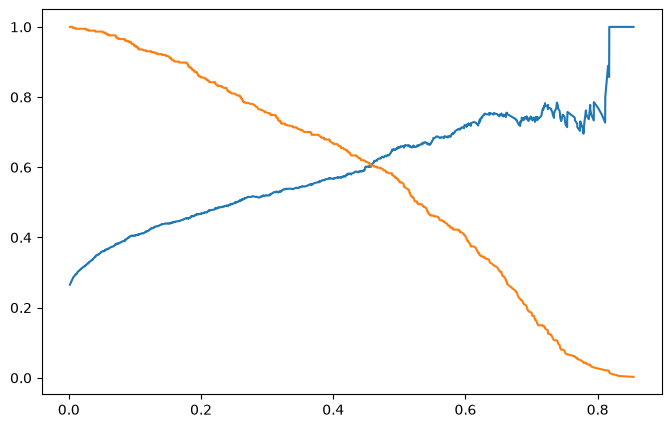

In [12]:
percision , recall, threshold = precision_recall_curve(y_test,y_proba)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(threshold, percision[:-1], label="Percision (churn)")
ax.plot(threshold, recall[:-1], label="Recall (churn)")
ax.axvline(0.5 , color= "grey",linestyle="__", label="Default cutoff (0.5)")

ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")

ax.set_title("Lowering the threshold buys recall at the cost of precision")
ax.legend()
ax.grid(alpha=0.3)
plt.show()
